# Shared marriage issues: keyword weights
Compare bride price and divorce across the two K=12 models. For bride price, compare official media T1 (Bride-price returns) with Weibo T4 (Bride price).

Weight = P(word | topic), calculated over each model's full vocabulary. The top 10 weights do not sum to 100%. Weights describe topic composition, not corpus word frequencies or statistical significance.

## 1. Load saved weights
Use verified weights from the original K=12 model settings.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebook").is_dir() and (p / "data").is_dir())
weights = pd.read_csv(project / "data" / "analysis_results" / "lda_k12_presentation" / "k12_keyword_weights.csv")
output = project / "data" / "analysis_results" / "lda_keyword_comparison"
(project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
(project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")).mkdir(parents=True, exist_ok=True)
output.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "Arial Unicode MS"

english = {
    "彩礼": "Bride price", "返还": "Return", "生活": "Life", "给付": "Payment",
    "情况": "Circumstances", "婚姻": "Marriage", "财物": "Money and property",
    "法院": "Court", "女方": "Woman's side", "结婚": "Getting married",
    "农村": "Rural areas", "移风易俗": "Custom reform", "高价彩礼": "High bride price",
    "治理": "Governance", "高额": "High amounts", "村民": "Villagers", "工作": "Work",
    "文明": "Civility", "零彩礼": "Zero bride price", "男人": "Men", "女人": "Women",
    "女生": "Girls / women", "男生": "Boys / men", "男方": "Man's side",
    "女孩": "Girls", "娶": "Marry a wife", "离婚": "Divorce", "子女": "Children",
    "财产": "Property", "夫妻": "Spouses", "一方": "One party", "判决": "Judgment",
    "民法典": "Civil Code", "协议": "Agreement", "离婚冷静期": "Divorce cooling-off period",
    "婚姻登记": "Marriage registration", "丈夫": "Husband", "家暴": "Domestic violence",
    "妻子": "Wife", "法律": "Law", "家庭": "Family", "父母": "Parents",
    "年轻人": "Young adults", "女性": "Women", "孩子": "Children", "社会": "Society",
    "人生": "Life course", "选择": "Choice", "爱情": "Love", "晚婚": "Late marriage",
    "经历": "Experiences", "一生": "Lifetime", "世界": "World",
}


## 2. Load full topic-word weights
Rebuild K=12 with the original settings once, then reuse the saved weights. Verify the original top-10 results before saving.

In [2]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

cache = (project / "data" / "model_cache" / output.relative_to(project / "data" / "analysis_results")) / "k12_word_weights.npz"
if not cache.exists():
    arrays = {}
    for corpus, min_df in [("official_media", 5), ("weibo_posts", 10)]:
        data = pd.read_csv(project / "data" / f"{corpus}_analysis.csv").dropna(subset=["tokens"])
        vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                     min_df=min_df, max_df=0.85, max_features=5000)
        X = vectorizer.fit_transform(data["tokens"])
        X = X[X.getnnz(axis=1) > 0]
        model = LatentDirichletAllocation(n_components=12, learning_method="online", max_iter=12,
                                         batch_size=512, random_state=42, n_jobs=4).fit(X)
        vocabulary = vectorizer.get_feature_names_out()
        probabilities = model.components_ / model.components_.sum(axis=1, keepdims=True) * 100
        # Check that reconstructed topics match the saved results.
        original = pd.read_csv(project / "data" / "analysis_results" / f"lda_{corpus}" / "k12_top10_keywords.csv")
        indices = model.components_.argsort(axis=1)[:, -10:][:, ::-1]
        assert np.array_equal(vocabulary[indices], original.iloc[:, 1:].to_numpy())
        for row in weights[weights["corpus"] == corpus].itertuples():
            j = np.flatnonzero(vocabulary == row.keyword)[0]
            assert abs(probabilities[row.topic - 1, j] - row.keyword_weight_pct) < 0.00006
        arrays[f"{corpus}_words"] = vocabulary.astype(str)
        arrays[f"{corpus}_weights"] = probabilities
        print(f"Verified {corpus}: original topic rankings and weights match.")
    np.savez_compressed(cache, **arrays)

with np.load(cache, allow_pickle=False) as saved:
    full_weights = {corpus: pd.DataFrame(saved[f"{corpus}_weights"],
                    columns=saved[f"{corpus}_words"], index=range(1, 13))
                    for corpus in ["official_media", "weibo_posts"]}


## 3. Compare aligned keywords with heatmaps
Align the union of both topics' top-10 words and use actual full-vocabulary weights. Both plots use a 0–9% color scale. A dash means the word is outside that model's vocabulary; values below 0.01% are labeled explicitly.

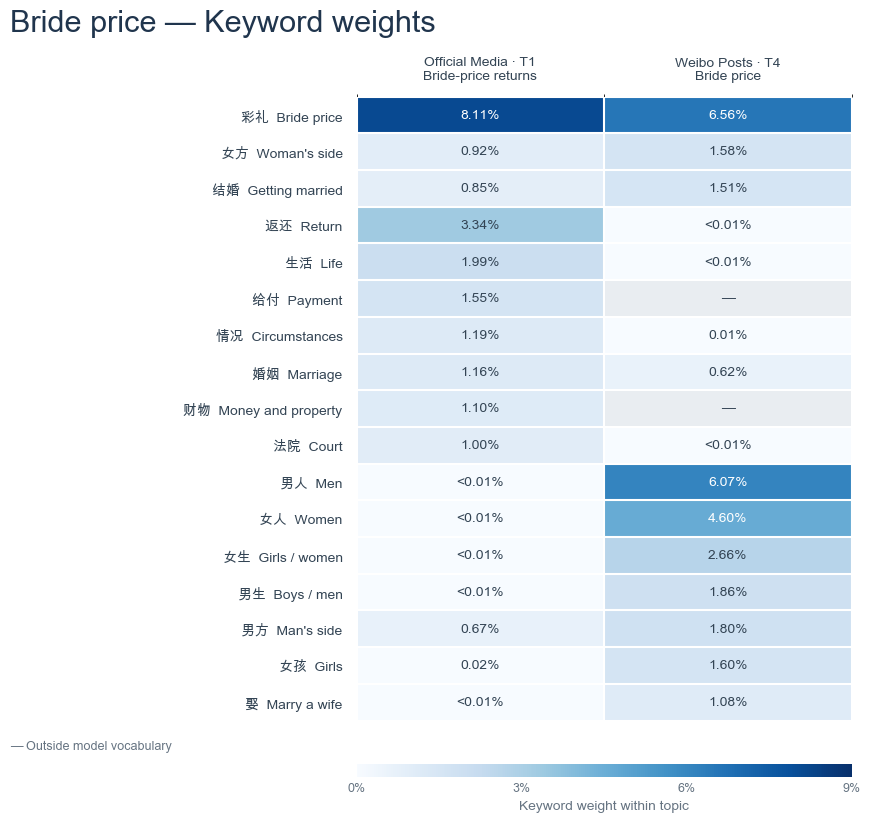

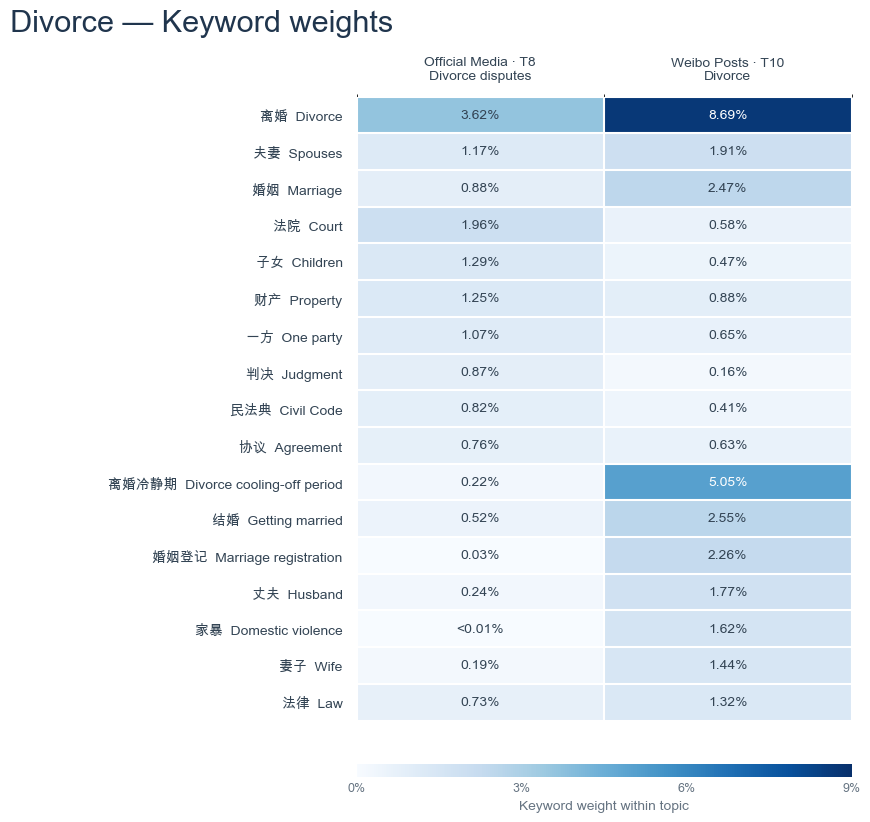

In [3]:
def plot_heatmap(title, panels, filename):
    top_words = []
    for corpus, topic, label in panels:
        top_words.append(weights[(weights["corpus"] == corpus) & (weights["topic"] == topic)]
                         .sort_values("keyword_rank")["keyword"].tolist())
    keywords = list(dict.fromkeys(word for group in top_words for word in group))
    keywords.sort(key=lambda word: -sum(word in group for group in top_words))
    matrix = np.array([[full_weights[corpus].at[topic, word]
                       if word in full_weights[corpus].columns else np.nan
                       for corpus, topic, label in panels] for word in keywords])
    labels = [f"{word}  {english[word]}" for word in keywords]
    fig, ax = plt.subplots(figsize=(9,
                                    0.36 * len(keywords) + 2.2), facecolor="white")
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#e9edf1")
    heat = ax.imshow(np.ma.masked_invalid(matrix), cmap=cmap, vmin=0, vmax=9, aspect="auto")
    ax.set_yticks(range(len(keywords)), labels, fontsize=10, color="#334454")
    ax.set_xticks(range(len(panels)), [label for corpus, topic, label in panels],
                  fontsize=10, color="#334454")
    ax.xaxis.tick_top()
    ax.tick_params(axis="both", length=0, pad=10)
    ax.set_xticks(np.arange(-0.5, len(panels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(keywords), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    for row in range(len(keywords)):
        for col in range(len(panels)):
            value = matrix[row, col]
            label = "—" if np.isnan(value) else ("<0.01%" if value < 0.01 else f"{value:.2f}%")
            ax.text(col, row, label, ha="center", va="center", fontsize=10,
                    color="white" if value >= 4.5 else "#334454")
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.suptitle(title, x=0.035, y=0.985, ha="left", fontsize=22, color="#20354d")
    fig.subplots_adjust(left=0.42, right=0.97, top=0.88, bottom=0.13)
    colorbar_ax = fig.add_axes([0.42, 0.062, 0.55, 0.016])
    colorbar = fig.colorbar(heat, cax=colorbar_ax, orientation="horizontal", ticks=[0, 3, 6, 9])
    colorbar.ax.set_xticklabels(["0%", "3%", "6%", "9%"])
    colorbar.ax.tick_params(length=0, labelsize=9, colors="#667482")
    colorbar.set_label("Keyword weight within topic", fontsize=10, color="#667482")
    colorbar.outline.set_visible(False)
    if np.isnan(matrix).any():
        fig.text(0.035, 0.095, "— Outside model vocabulary", fontsize=9, color="#667482")
    fig.savefig((project / "data" / "generated_figures" / output.relative_to(project / "data" / "analysis_results")) / filename, dpi=220, facecolor="white", bbox_inches="tight")
    plt.show()

plot_heatmap("Bride price — Keyword weights", [
    ("official_media", 1, "Official Media · T1\nBride-price returns"),
    ("weibo_posts", 4, "Weibo Posts · T4\nBride price"),
], "bride_price_keyword_heatmap.png")

plot_heatmap("Divorce — Keyword weights", [
    ("official_media", 8, "Official Media · T8\nDivorce disputes"),
    ("weibo_posts", 10, "Weibo Posts · T10\nDivorce"),
], "divorce_keyword_heatmap.png")
